# Análisis univariante y bivariante: Salud del sueño y estilo de vida


---


## Tabla de contenidos

1. Contexto y objetivo
2. Repaso muy breve de Pandas
3. Análisis univariante
4. Visualización univariante
5. Análisis bivariante
6. Visualizaciones bivariantes
7. Parte práctica
8. Cierre

# 1. Contexto y objetivo

## 1.1 ¿Qué representa cada registro?

Cada fila del conjunto de datos representa **a una persona adulta** (entre 27 y 59 años) de la cual se registran datos de sueño, hábitos de vida y salud. En terminología de ciencia de datos:

- **Unidad de análisis (observación):** una persona.
- **Variable:** una característica medida en cada persona (edad, horas de sueño, nivel de estrés, etc.).
- **Conjunto de datos (dataset):** la colección de las 374 observaciones.

## 1.2 Nota sobre el origen de los datos

El conjunto de datos de este notebook pertenencen al dataset público *Sleep Health and Lifestyle*.

## 1.3 Diccionario de variables

| Variable | Tipo estadístico | Escala de medición | Descripción |
|---|---|---|---|
| `Person ID` | Identificador | Nominal | Código único de cada persona. No es una variable analítica. |
| `Gender` | Categórica | Nominal | Género de la persona (Male / Female). |
| `Age` | Numérica discreta | Razón | Edad en años cumplidos. |
| `Occupation` | Categórica | Nominal | Ocupación o profesión. |
| `Sleep Duration` | Numérica continua | Razón | Horas de sueño por día. |
| `Quality of Sleep` | Numérica discreta (ordinal) | Ordinal | Calificación subjetiva de la calidad del sueño, de 1 a 10. |
| `Physical Activity Level` | Numérica discreta | Razón | Minutos de actividad física por día. |
| `Stress Level` | Numérica discreta (ordinal) | Ordinal | Calificación subjetiva del estrés, de 1 a 10. |
| `BMI Category` | Categórica ordinal | Ordinal | Categoría de índice de masa corporal (Normal, Overweight, Obese). |
| `Blood Pressure` | Texto | Nominal (formato sistólica/diastólica) | Presión arterial, por ejemplo `120/80`. Se separará en dos variables numéricas. |
| `Heart Rate` | Numérica discreta | Razón | Frecuencia cardíaca en reposo, en latidos por minuto. |
| `Daily Steps` | Numérica discreta | Razón | Pasos diarios. |
| `Sleep Disorder` | Categórica | Nominal | Presencia de trastorno del sueño (None, Insomnia, Sleep Apnea). |

### Conceptos clave sobre escalas de medición

- **Nominal:** categorías sin orden natural (género, ocupación).
- **Ordinal:** categorías con un orden, pero cuya distancia entre niveles no es necesariamente uniforme (nivel de estrés de 1 a 10, categoría de IMC).
- **De razón:** valores numéricos con cero absoluto, donde tiene sentido decir "el doble de" (minutos de actividad, pasos).

> Las variables ordinales codificadas con números (como estrés de 1 a 10) suelen tratarse como numéricas para calcular promedios, pero su interpretación debe hacerse con cautela, porque la diferencia entre 3 y 4 no tiene por qué ser equivalente a la diferencia entre 7 y 8.

## 1.4 Explorar vs. analizar

| | Análisis exploratorio (EDA) | Análisis confirmatorio / inferencial |
|---|---|---|
| **Propósito** | Conocer los datos, detectar patrones, anomalías y generar preguntas. | Probar hipótesis formales y cuantificar la incertidumbre. |
| **Herramientas** | Estadísticos descriptivos, gráficos, tablas de frecuencias, correlaciones. | Pruebas de hipótesis, intervalos de confianza, modelos. |
| **Resultado** | Descripciones y posibles hipótesis. | Decisiones respaldadas estadísticamente. |

Este notebook corresponde al **análisis exploratorio**. Sus hallazgos son indicios, no pruebas definitivas.

## 1.5 Objetivo del notebook

Aprender a **describir una variable** (univariante) y a **describir la relación entre dos variables** (bivariante), y a convertir esos resultados en interpretaciones y conclusiones respaldadas por evidencia.

## 1.6 Configuración del entorno

Importamos las bibliotecas que se usarán en todo el notebook:

- **pandas:** manipulación y análisis de datos tabulares.
- **numpy:** operaciones numéricas.
- **matplotlib:** biblioteca base de visualización.
- **seaborn:** visualización estadística de más alto nivel, construida sobre matplotlib.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# 2. Repaso muy breve de Pandas

Esta sección es únicamente un punto de partida. Estas operaciones ya fueron trabajadas en sesiones anteriores.

| Instrucción | Para qué sirve |
|---|---|
| `pd.read_csv()` | Lee un archivo CSV y lo convierte en un DataFrame. |
| `head()` | Muestra las primeras filas. |
| `shape` | Devuelve (número de filas, número de columnas). |
| `info()` | Resume tipos de dato y valores no nulos por columna. |
| `isnull()` | Marca con `True` los valores faltantes; combinado con `sum()` los cuenta por columna. |

In [3]:
# keep_default_na=False evita que pandas interprete el texto "None" como valor faltante
df = pd.read_csv("../BDD/Sleep.csv", keep_default_na=False)
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.10,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.20,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.20,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.90,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.90,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [4]:
print("Filas y columnas:", df.shape)

Filas y columnas: (374, 13)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


In [6]:
# Conteo de valores faltantes por columna
df.isnull().sum()

Person ID                  0
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Blood Pressure             0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
dtype: int64

**Advertencia sobre la categoría `None`.** En la variable `Sleep Disorder`, el texto `None` significa "sin trastorno" y es una categoría legítima. Por defecto, `pd.read_csv()` interpreta el texto `None` como valor faltante (`NaN`), lo que borraría silenciosamente a las personas sin trastorno. Por eso se usa el argumento `keep_default_na=False`. Este es un ejemplo de por qué conviene verificar siempre `isnull()` y las frecuencias tras cargar los datos.

**Lectura del resultado.** El dataset tiene 374 observaciones y 13 variables, sin valores faltantes. La columna `Blood Pressure` es de tipo texto (`object`) porque almacena valores como `120/80`; antes de analizarla numéricamente debemos separarla.

## 2.1 Preparación de los datos

Antes del análisis creamos dos variables numéricas a partir de `Blood Pressure`:

- `Systolic`: presión sistólica (el número antes de la barra).
- `Diastolic`: presión diastólica (el número después de la barra).

También definimos un orden explícito para `BMI Category`, porque es una variable ordinal y queremos que los gráficos y tablas respeten ese orden.

> **Por qué importa:** una variable que parece numérica pero está almacenada como texto no puede resumirse con media o desviación estándar. Verificar los tipos de dato es siempre el primer paso.

In [7]:
# Separar la presión arterial en dos variables numéricas
bp = df["Blood Pressure"].str.split("/", expand=True).astype(int)
df["Systolic"] = bp[0]
df["Diastolic"] = bp[1]

# Orden explícito para la variable ordinal
orden_bmi = ["Normal", "Overweight", "Obese"]
df["BMI Category"] = pd.Categorical(df["BMI Category"], categories=orden_bmi, ordered=True)

# Orden para trastornos del sueño
orden_trastorno = ["None", "Insomnia", "Sleep Apnea"]
df["Sleep Disorder"] = pd.Categorical(df["Sleep Disorder"], categories=orden_trastorno, ordered=False)

df[["Blood Pressure", "Systolic", "Diastolic"]].head()

,Blood Pressure,Systolic,Diastolic
0,126/83,126,83
1,125/80,125,80
2,125/80,125,80
3,140/90,140,90
4,140/90,140,90


In [8]:
# Clasificación de variables que se usará durante el notebook
variables_numericas = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
                       "Stress Level", "Heart Rate", "Daily Steps", "Systolic", "Diastolic"]
variables_categoricas = ["Gender", "Occupation", "BMI Category", "Sleep Disorder"]

print("Numéricas:", len(variables_numericas), "| Categóricas:", len(variables_categoricas))

Numéricas: 9 | Categóricas: 4


# 3. Análisis univariante

## 3.1 ¿Qué significa?

El **análisis univariante** estudia **una sola variable a la vez**. Su propósito es describir cómo se comporta: dónde se concentran sus valores, cuánto varían, qué forma tiene su distribución y si existen valores inusuales.

Preguntas típicas del análisis univariante:

- ¿Cuál es el valor típico?
- ¿Qué tan dispersos están los datos?
- ¿Hay valores extremos?
- ¿Qué categoría es la más frecuente?

## 3.2 Variables numéricas vs. categóricas

El tipo de variable determina qué técnicas son válidas.

| | Variable numérica | Variable categórica |
|---|---|---|
| **Qué representa** | Cantidades medibles. | Categorías o etiquetas. |
| **Resumen numérico** | Media, mediana, desviación estándar, cuartiles. | Frecuencias absolutas y relativas, moda. |
| **Gráficos** | Histograma, boxplot. | Gráfico de barras. |
| **Ejemplo** | `Sleep Duration`, `Age`. | `Gender`, `Sleep Disorder`. |

Calcular una media de `Gender` no tiene sentido; calcular una frecuencia de `Sleep Duration` sin agrupar tampoco aporta mucho. Elegir la técnica correcta depende de reconocer primero el tipo de variable.

## 3.3 Medidas de tendencia central

Resumen del **valor típico** o central de una variable.

### Media aritmética

Suma de todos los valores dividida entre el número de observaciones.

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$

Es sensible a valores extremos: un solo dato muy alto o muy bajo puede desplazarla.

### Mediana

Valor que deja el 50 % de las observaciones por debajo y el 50 % por encima cuando los datos están ordenados. **No se ve afectada por valores extremos**, por lo que es más robusta que la media.

### Moda

Valor que **más se repite**. Es la única medida de tendencia central aplicable a variables categóricas. Puede haber más de una moda.

### Cómo comparar media y mediana

- Media ≈ mediana: distribución aproximadamente simétrica.
- Media > mediana: posible asimetría hacia la derecha (cola larga de valores altos).
- Media < mediana: posible asimetría hacia la izquierda (cola larga de valores bajos).

In [9]:
col = "Sleep Duration"

media = df[col].mean()
mediana = df[col].median()
moda = df[col].mode()

print(f"Media:   {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Moda:    {list(moda.round(2))}")

Media:   7.13
Mediana: 7.20
Moda:    [7.2]


**Cómo leer este resultado.** Las tres cifras son valores en horas de sueño. Si media y mediana son cercanas, la distribución es aproximadamente simétrica. Observe que la moda puede devolver más de un valor cuando hay empates.

## 3.4 Medidas de dispersión

Indican **qué tan separados** están los datos entre sí. Dos conjuntos pueden tener la misma media y comportarse de forma muy distinta.

### Mínimo y máximo

Los valores más pequeño y más grande observados.

### Rango

$$\text{Rango} = \max(x) - \min(x)$$

Es simple de calcular pero depende solo de dos observaciones, por lo que es muy sensible a valores extremos.

### Varianza y desviación estándar

La **varianza** es el promedio de los cuadrados de las desviaciones respecto a la media:

$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})^2$$

La **desviación estándar** es su raíz cuadrada, $s = \sqrt{s^2}$, y tiene la ventaja de estar en las **mismas unidades** que la variable original. Una desviación estándar pequeña indica datos concentrados alrededor de la media; una grande, datos dispersos.

> Pandas usa por defecto el divisor $n-1$ (desviación estándar muestral).

### Coeficiente de variación

$$CV = \frac{s}{\bar{x}} \times 100$$

Expresa la dispersión como porcentaje de la media. Permite **comparar la dispersión de variables con unidades distintas** (por ejemplo, pasos diarios frente a horas de sueño).

In [10]:
print(f"Mínimo:              {df[col].min():.2f}")
print(f"Máximo:              {df[col].max():.2f}")
print(f"Rango:               {df[col].max() - df[col].min():.2f}")
print(f"Varianza:            {df[col].var():.3f}")
print(f"Desviación estándar: {df[col].std():.3f}")
print(f"Coef. de variación:  {df[col].std() / df[col].mean() * 100:.2f} %")

Mínimo:              5.80
Máximo:              8.50
Rango:               2.70
Varianza:            0.633
Desviación estándar: 0.796
Coef. de variación:  11.16 %


In [11]:
# Comparar la dispersión relativa de varias variables con unidades distintas
comparacion = pd.DataFrame({
    "media": df[variables_numericas].mean(),
    "desv_std": df[variables_numericas].std(),
})
comparacion["CV_%"] = comparacion["desv_std"] / comparacion["media"] * 100
comparacion.sort_values("CV_%", ascending=False)

,media,desv_std,CV_%
Physical Activity Level,59.17,20.83,35.20
Stress Level,5.39,1.77,32.95
Daily Steps,"6,816.84","1,617.92",23.73
Age,42.18,8.67,20.56
Quality of Sleep,7.31,1.20,16.37
Sleep Duration,7.13,0.80,11.16
Diastolic,84.65,6.16,7.28
Systolic,128.55,7.75,6.03
Heart Rate,70.17,4.14,5.89


**Cómo leer este resultado.** La desviación estándar por sí sola no permite comparar variables con unidades distintas. El coeficiente de variación sí: las variables con mayor `CV_%` son relativamente más dispersas respecto a su propia media.

## 3.5 Medidas de posición: cuartiles y percentiles

Describen **en qué lugar de la distribución** se ubica un valor.

- **Cuartil 1 (Q1):** deja por debajo al 25 % de los datos.
- **Cuartil 2 (Q2):** es la mediana (50 %).
- **Cuartil 3 (Q3):** deja por debajo al 75 % de los datos.
- **Rango intercuartílico (IQR):** $IQR = Q_3 - Q_1$. Contiene el 50 % central de los datos y es una medida de dispersión robusta.
- **Percentil p:** valor bajo el cual se encuentra el p % de los datos. Los cuartiles son los percentiles 25, 50 y 75.

### Regla de Tukey para valores potencialmente atípicos

Se consideran **potencialmente atípicos** los valores fuera del intervalo:

$$[\,Q_1 - 1.5 \cdot IQR,\; Q_3 + 1.5 \cdot IQR\,]$$

El término *potencialmente* es importante: un valor fuera de ese rango no es necesariamente un error. Puede ser un dato legítimo pero poco común, y su tratamiento depende del contexto.

In [12]:
q1 = df[col].quantile(0.25)
q2 = df[col].quantile(0.50)
q3 = df[col].quantile(0.75)
iqr = q3 - q1

limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

print(f"Q1: {q1:.2f} | Q2 (mediana): {q2:.2f} | Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Límites de Tukey: [{limite_inf:.2f}, {limite_sup:.2f}]")

atipicos = df[(df[col] < limite_inf) | (df[col] > limite_sup)]
print(f"Valores fuera de los límites: {len(atipicos)}")

Q1: 6.40 | Q2 (mediana): 7.20 | Q3: 7.80
IQR: 1.40
Límites de Tukey: [4.30, 9.90]
Valores fuera de los límites: 0


In [13]:
# Percentiles específicos
df[col].quantile([0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95])

0.05   6.00
0.10   6.10
0.25   6.40
0.50   7.20
0.75   7.80
0.90   8.20
0.95   8.40
Name: Sleep Duration, dtype: float64

## 3.6 La función `describe()`

`describe()` reúne en una sola llamada las principales medidas numéricas: conteo, media, desviación estándar, mínimo, cuartiles y máximo. Es el punto de partida habitual de todo análisis univariante.

Para variables categóricas, `describe()` devuelve el conteo, el número de categorías distintas (`unique`), la moda (`top`) y su frecuencia (`freq`).

In [14]:
df[variables_numericas].describe()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic
count,374.00,374.00,374.00,374.00,374.00,374.00,374.00,374.00,374.00
mean,42.18,7.13,7.31,59.17,5.39,70.17,"6,816.84",128.55,84.65
std,8.67,0.80,1.20,20.83,1.77,4.14,"1,617.92",7.75,6.16
min,27.00,5.80,4.00,30.00,3.00,65.00,"3,000.00",115.00,75.00
25%,35.25,6.40,6.00,45.00,4.00,68.00,"5,600.00",125.00,80.00
50%,43.00,7.20,7.00,60.00,5.00,70.00,"7,000.00",130.00,85.00
75%,50.00,7.80,8.00,75.00,7.00,72.00,"8,000.00",135.00,90.00
max,59.00,8.50,9.00,90.00,8.00,86.00,"10,000.00",142.00,95.00


In [15]:
df[variables_categoricas].describe()

,Gender,Occupation,BMI Category,Sleep Disorder
count,374,374,353,374
unique,2,11,3,3
top,Male,Nurse,Normal,None
freq,189,73,195,219


**Qué observar al leer `describe()`:**

1. Compare `mean` y `50%` (mediana): ¿son similares?
2. Compare `min` y `max` con lo que se esperaría para la variable: ¿tienen sentido?
3. Compare `std` con `mean`: ¿la dispersión es grande o pequeña en términos relativos?
4. Compare la distancia de `min` a `25%` con la de `75%` a `max`: indica posible asimetría.

## 3.7 Análisis univariante de variables categóricas

Para una variable categórica se usan **frecuencias**:

- **Frecuencia absoluta:** cuántas observaciones hay en cada categoría.
- **Frecuencia relativa (proporción):** frecuencia absoluta dividida entre el total.
- **Porcentaje:** proporción multiplicada por 100.
- **Moda:** categoría con mayor frecuencia.

In [16]:
def tabla_frecuencias(serie):
    abs_ = serie.value_counts()
    rel = serie.value_counts(normalize=True) * 100
    return pd.DataFrame({"frecuencia": abs_, "porcentaje_%": rel.round(1)})

tabla_frecuencias(df["Sleep Disorder"])

,frecuencia,porcentaje_%
Sleep Disorder,,
None,219,58.60
Sleep Apnea,78,20.90
Insomnia,77,20.60


In [17]:
tabla_frecuencias(df["BMI Category"])

,frecuencia,porcentaje_%
BMI Category,,
Normal,195,55.20
Overweight,148,41.90
Obese,10,2.80


In [18]:
tabla_frecuencias(df["Occupation"])

,frecuencia,porcentaje_%
Occupation,,
Nurse,73,19.50
Doctor,71,19.00
Engineer,63,16.80
Lawyer,47,12.60
Teacher,40,10.70
Accountant,37,9.90
Salesperson,32,8.60
Scientist,4,1.10
Software Engineer,4,1.10


**Cómo leer este resultado.** Cuando una variable tiene muchas categorías (como `Occupation`), algunas pueden tener muy pocos casos. Esto limita la confiabilidad de cualquier comparación que las involucre: un porcentaje calculado sobre 4 personas es mucho menos estable que uno calculado sobre 70.

# 4. Visualización univariante

## 4.1 ¿Por qué visualizar?

Los estadísticos resumen reducen una variable a unos pocos números. Los gráficos muestran **la forma completa de la distribución**, que los números no siempre revelan: asimetrías, varios picos, huecos o agrupaciones.

## 4.2 Histograma

Divide el rango de una variable numérica en intervalos (*bins*) y muestra cuántas observaciones caen en cada uno.

**Qué permite observar:**

- **Forma:** simétrica, asimétrica a la derecha o a la izquierda.
- **Modalidad:** unimodal (un pico), bimodal (dos picos) o multimodal.
- **Concentración:** dónde se acumula la mayoría de los datos.
- **Dispersión:** qué tan extendida es la distribución.

> **Advertencia:** el número de intervalos cambia la apariencia del histograma. Con pocos intervalos se pierde detalle; con demasiados aparece ruido. Conviene probar varios valores.

Se superpone una **curva de densidad (KDE)**, una estimación suavizada de la distribución.

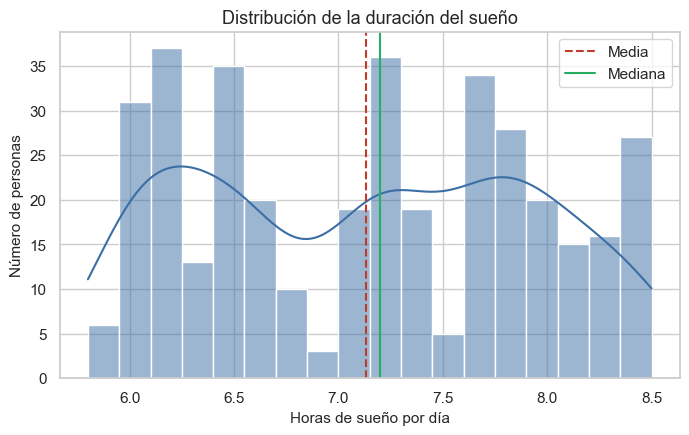

In [22]:
fig, ax = plt.subplots()
sns.histplot(df["Sleep Duration"], bins=18, kde=True, color="#3b6ea5", ax=ax)
ax.axvline(df["Sleep Duration"].mean(), color="#c0392b", linestyle="--", label="Media")
ax.axvline(df["Sleep Duration"].median(), color="#27ae60", linestyle="-", label="Mediana")
ax.set_title("Distribución de la duración del sueño")
ax.set_xlabel("Horas de sueño por día")
ax.set_ylabel("Número de personas")
ax.legend()
plt.show()

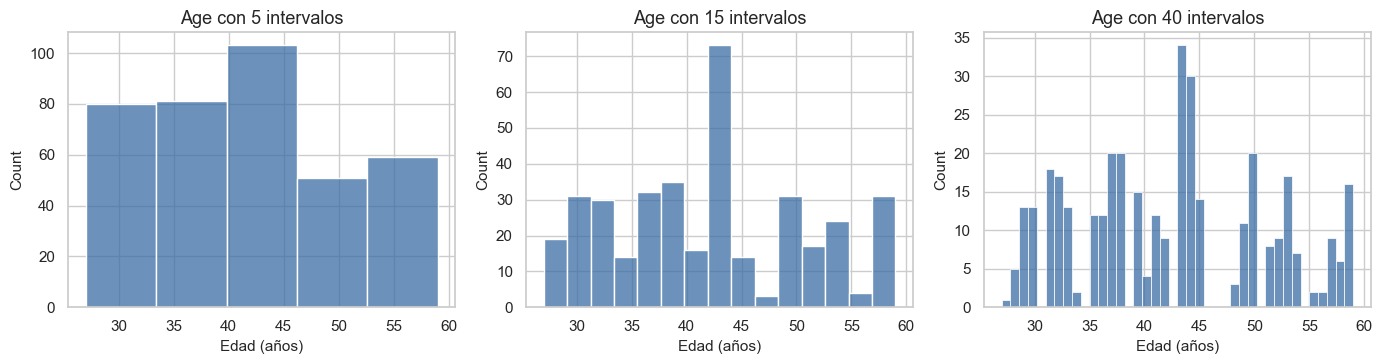

In [23]:
# Efecto del número de intervalos sobre la apariencia del histograma
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for ax, b in zip(axes, [5, 15, 40]):
    sns.histplot(df["Age"], bins=b, color="#3b6ea5", ax=ax)
    ax.set_title(f"Age con {b} intervalos")
    ax.set_xlabel("Edad (años)")
plt.tight_layout()
plt.show()

**Cómo leer este resultado.** Observe cómo el mismo conjunto de datos de `Age` se ve distinto según el número de intervalos. Una buena práctica es no basar una interpretación en un solo histograma.

## 4.3 Boxplot (diagrama de caja)

Resume una distribución numérica con cinco valores: mínimo, Q1, mediana, Q3 y máximo, más los puntos potencialmente atípicos.

**Cómo se lee:**

- La **caja** va de Q1 a Q3 (contiene el 50 % central).
- La **línea dentro de la caja** es la mediana.
- Los **bigotes** se extienden hasta el dato más lejano dentro de $1.5 \cdot IQR$ de la caja.
- Los **puntos** más allá de los bigotes son valores potencialmente atípicos.

El boxplot es excelente para ver **simetría, dispersión y atípicos**, pero no muestra picos múltiples; el histograma complementa esa limitación.

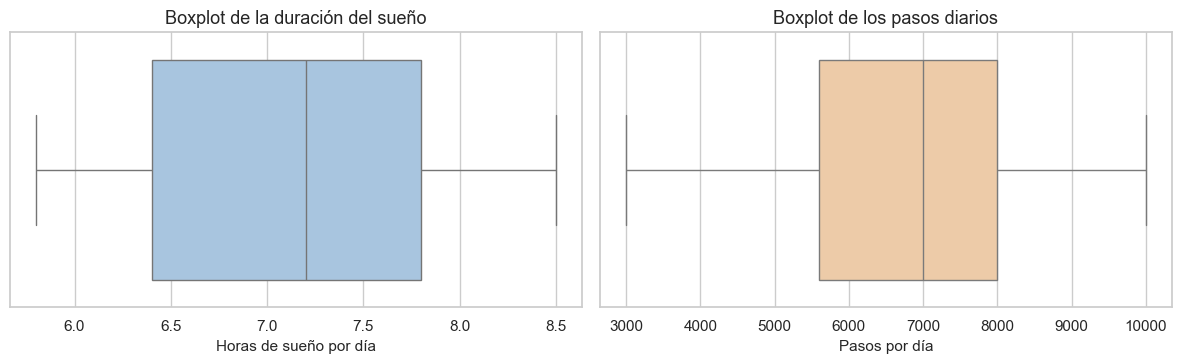

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

sns.boxplot(x=df["Sleep Duration"], color="#9fc5e8", ax=axes[0])
axes[0].set_title("Boxplot de la duración del sueño")
axes[0].set_xlabel("Horas de sueño por día")

sns.boxplot(x=df["Daily Steps"], color="#f9cb9c", ax=axes[1])
axes[1].set_title("Boxplot de los pasos diarios")
axes[1].set_xlabel("Pasos por día")

plt.tight_layout()
plt.show()

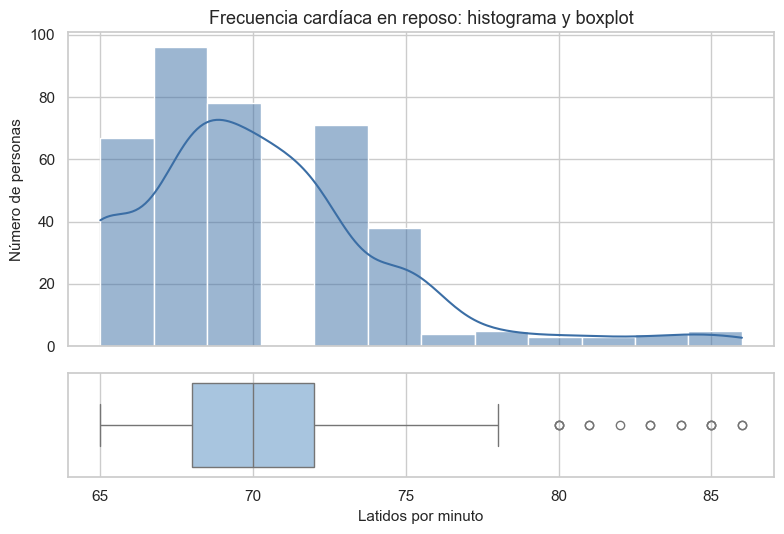

In [25]:
# Histograma y boxplot alineados: se complementan
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})
sns.histplot(df["Heart Rate"], bins=12, kde=True, color="#3b6ea5", ax=ax1)
ax1.set_title("Frecuencia cardíaca en reposo: histograma y boxplot")
ax1.set_ylabel("Número de personas")
sns.boxplot(x=df["Heart Rate"], color="#9fc5e8", ax=ax2)
ax2.set_xlabel("Latidos por minuto")
plt.tight_layout()
plt.show()

## 4.4 Valores potencialmente atípicos

Un valor atípico (*outlier*) es una observación que se aleja notablemente del resto. Conviene distinguir tres situaciones:

1. **Error de captura o medición** (por ejemplo, una edad de 250 años): se corrige o se elimina.
2. **Valor legítimo pero extremo** (por ejemplo, una persona que camina 20 000 pasos): se conserva y se reporta.
3. **Valor de un subgrupo distinto:** puede indicar que existe una población diferente mezclada en los datos.

Detectar un valor atípico es solo el primer paso; **decidir qué hacer con él requiere conocer el contexto**.

In [26]:
def resumen_atipicos(df, columnas):
    filas = []
    for c in columnas:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((df[c] < li) | (df[c] > ls)).sum()
        filas.append({"variable": c, "limite_inf": li, "limite_sup": ls,
                      "n_atipicos": n_out, "porcentaje_%": n_out / len(df) * 100})
    return pd.DataFrame(filas).set_index("variable")

resumen_atipicos(df, variables_numericas)

,limite_inf,limite_sup,n_atipicos,porcentaje_%
variable,,,,
Age,13.12,72.12,0,0.00
Sleep Duration,4.30,9.90,0,0.00
Quality of Sleep,3.00,11.00,0,0.00
Physical Activity Level,0.00,120.00,0,0.00
Stress Level,-0.50,11.50,0,0.00
Heart Rate,62.00,78.00,15,4.01
Daily Steps,"2,000.00","11,600.00",0,0.00
Systolic,110.00,150.00,0,0.00
Diastolic,65.00,105.00,0,0.00


**Cómo leer este resultado.** Una variable con `n_atipicos = 0` no presenta valores fuera de la regla de Tukey. Las variables con atípicos deben revisarse caso por caso antes de decidir si se mantienen.

## 4.5 Gráfico de barras y frecuencias

Para variables categóricas se usa el **gráfico de barras**: una barra por categoría, cuya altura es la frecuencia.

**Buenas prácticas:**

- Las barras **tienen espacio entre sí** (a diferencia del histograma, porque las categorías son discretas).
- Si la variable es nominal, ordenar las barras por frecuencia facilita la lectura.
- Si la variable es ordinal, respetar el orden natural de las categorías.
- Considerar porcentajes cuando se comparan grupos de distinto tamaño.

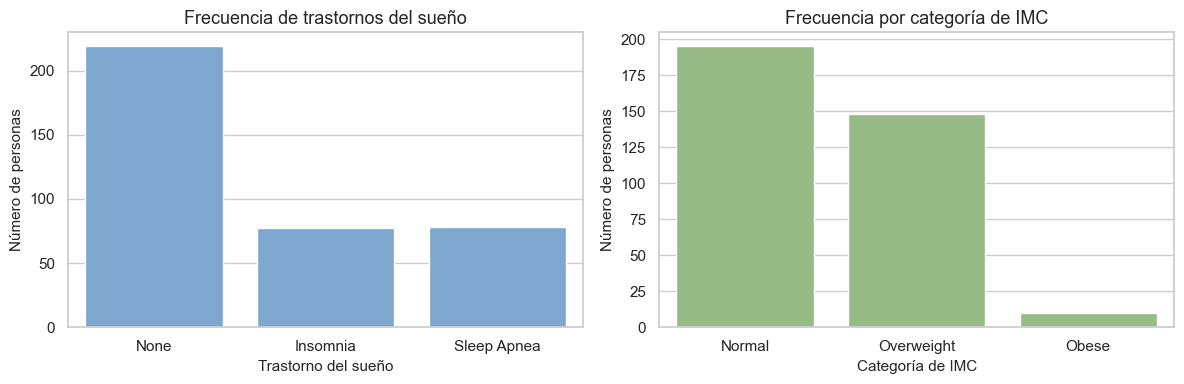

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x="Sleep Disorder", order=orden_trastorno, color="#6fa8dc", ax=axes[0])
axes[0].set_title("Frecuencia de trastornos del sueño")
axes[0].set_xlabel("Trastorno del sueño")
axes[0].set_ylabel("Número de personas")

sns.countplot(data=df, x="BMI Category", order=orden_bmi, color="#93c47d", ax=axes[1])
axes[1].set_title("Frecuencia por categoría de IMC")
axes[1].set_xlabel("Categoría de IMC")
axes[1].set_ylabel("Número de personas")

plt.tight_layout()
plt.show()

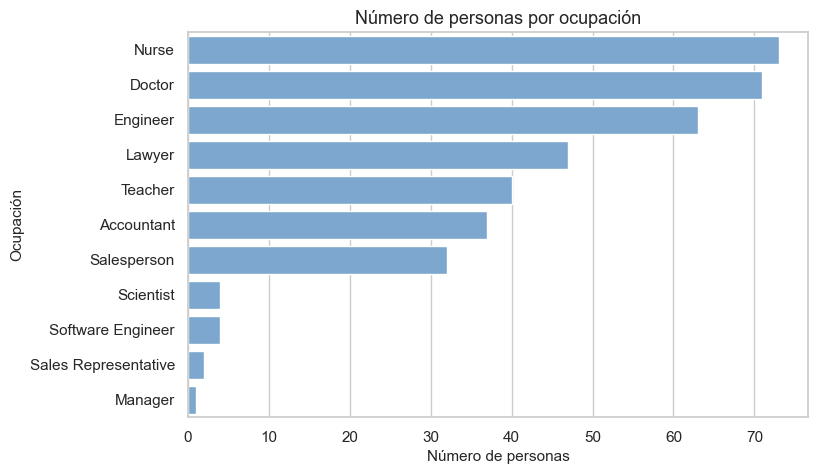

In [28]:
# Variable con muchas categorías: barras horizontales ordenadas por frecuencia
orden_ocupacion = df["Occupation"].value_counts().index

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, y="Occupation", order=orden_ocupacion, color="#6fa8dc", ax=ax)
ax.set_title("Número de personas por ocupación")
ax.set_xlabel("Número de personas")
ax.set_ylabel("Ocupación")
plt.show()

## 4.6 Interpretación de distribuciones

Al describir la forma de una distribución numérica, se evalúan cuatro aspectos:

| Aspecto | Pregunta | Posibles respuestas |
|---|---|---|
| **Centro** | ¿Alrededor de qué valor se concentran los datos? | Media, mediana. |
| **Dispersión** | ¿Qué tan extendidos están? | Desviación estándar, rango, IQR. |
| **Forma** | ¿Es simétrica? ¿Tiene cola? | Simétrica, asimétrica a la derecha o a la izquierda. |
| **Valores inusuales** | ¿Hay datos alejados del resto? | Atípicos, huecos, picos múltiples. |

### Coeficiente de asimetría

Pandas ofrece `skew()`:

- Cercano a **0**: distribución simétrica.
- **Positivo:** cola más larga hacia la derecha.
- **Negativo:** cola más larga hacia la izquierda.

Como regla orientativa, valores entre -0.5 y 0.5 indican simetría aproximada.

In [29]:
resumen_forma = pd.DataFrame({
    "media": df[variables_numericas].mean(),
    "mediana": df[variables_numericas].median(),
    "desv_std": df[variables_numericas].std(),
    "asimetria": df[variables_numericas].skew(),
})
resumen_forma["media_menos_mediana"] = resumen_forma["media"] - resumen_forma["mediana"]
resumen_forma.round(3)

,media,mediana,desv_std,asimetria,media_menos_mediana
Age,42.18,43.00,8.67,0.26,-0.82
Sleep Duration,7.13,7.20,0.80,0.04,-0.07
Quality of Sleep,7.31,7.00,1.20,-0.21,0.31
Physical Activity Level,59.17,60.00,20.83,0.07,-0.83
Stress Level,5.38,5.00,1.77,0.15,0.39
Heart Rate,70.17,70.00,4.14,1.23,0.17
Daily Steps,"6,816.85","7,000.00","1,617.92",0.18,-183.16
Systolic,128.55,130.00,7.75,-0.04,-1.45
Diastolic,84.65,85.00,6.16,0.38,-0.35


### Ejemplo guiado: de resultado a conclusión

Tomemos la variable `Stress Level` y recorramos los cuatro niveles de lenguaje analítico.

In [30]:
est = df["Stress Level"]
print(f"Media:    {est.mean():.2f}")
print(f"Mediana:  {est.median():.2f}")
print(f"Desv. std: {est.std():.2f}")
print(f"Mín - Máx: {est.min()} - {est.max()}")
print(f"Asimetría: {est.skew():.2f}")

Media:    5.39
Mediana:  5.00
Desv. std: 1.77
Mín - Máx: 3 - 8
Asimetría: 0.15


Para escribir un buen análisis, se separan cuatro niveles:

1. **Resultado numérico:** `Stress Level.mean()` devuelve un número. Un número solo no comunica nada.
2. **Descripción:** redacta ese número en lenguaje natural con unidades y contexto. *"El nivel de estrés promedio de los participantes es de aproximadamente 5.4 sobre una escala de 1 a 10."*
3. **Interpretación:** explica qué significa la forma de la distribución y qué implica. *"La media y la mediana son similares y la asimetría es cercana a cero, por lo que la distribución es aproximadamente simétrica; los valores se concentran en la zona media de la escala, con dispersión moderada."*
4. **Conclusión:** afirma algo acotado al dataset y respaldado por la evidencia. *"Dentro de este conjunto de datos, los participantes presentan niveles de estrés principalmente moderados, sin una concentración marcada en los extremos de la escala."*

Una conclusión **no debe afirmar más de lo que los datos permiten**: no generaliza a toda la población ni establece causas.

# 5. Análisis bivariante

## 5.1 ¿Qué significa?

El **análisis bivariante** estudia **dos variables al mismo tiempo** para determinar si existe una relación entre ellas y de qué tipo. Responde preguntas como:

- ¿Las personas que duermen más reportan mejor calidad de sueño?
- ¿El nivel de estrés es distinto entre hombres y mujeres?
- ¿El tipo de trastorno del sueño se distribuye de forma diferente según la categoría de IMC?

## 5.2 Selección de la técnica según los tipos de variables

| Combinación | Técnica numérica | Visualización |
|---|---|---|
| **Numérica ↔ Numérica** | Covarianza, coeficiente de correlación. | Diagrama de dispersión (`scatterplot`). |
| **Categórica ↔ Numérica** | Estadísticos descriptivos por grupo (`groupby`). | Boxplot por grupos, histogramas por grupos. |
| **Categórica ↔ Categórica** | Tabla de contingencia (`crosstab`), porcentajes por fila o columna. | Gráfico de barras agrupado o apilado (`countplot` con `hue`). |

## 5.3 Concepto fundamental: asociación no es causalidad

Que dos variables estén relacionadas **no implica que una cause la otra**. Una asociación puede deberse a:

- Causalidad en una dirección o en la otra.
- Una tercera variable que afecta a ambas (**variable de confusión**).
- Coincidencia, especialmente con pocos datos.

En un análisis exploratorio se habla de **asociación**, **relación** o **tendencia**; se evitan verbos como *causa*, *provoca* o *produce*.

## 5.4 Numérica ↔ Numérica

### Covarianza

Mide si dos variables **tienden a variar juntas**:

$$\text{cov}(X,Y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})$$

- Positiva: cuando una sube, la otra tiende a subir.
- Negativa: cuando una sube, la otra tiende a bajar.
- Su magnitud depende de las unidades, por lo que **no es comparable** entre pares de variables distintos.

### Coeficiente de correlación de Pearson

Es la covarianza estandarizada, por lo que siempre está entre -1 y 1:

$$r = \frac{\text{cov}(X,Y)}{s_X \, s_Y}$$

| Valor de $|r|$ | Interpretación orientativa |
|---|---|
| 0.00 - 0.19 | Muy débil o nula |
| 0.20 - 0.39 | Débil |
| 0.40 - 0.59 | Moderada |
| 0.60 - 0.79 | Fuerte |
| 0.80 - 1.00 | Muy fuerte |

**Limitaciones de Pearson:**

- Mide únicamente **relaciones lineales**. Una relación curva puede producir $r$ cercano a 0.
- Es sensible a valores atípicos.
- **Siempre debe acompañarse de un diagrama de dispersión.**

### Correlación de Spearman

Calcula la correlación sobre los **rangos** (posiciones ordenadas) de los datos. Es apropiada para variables ordinales y para relaciones monótonas no necesariamente lineales; es más robusta frente a atípicos.

In [31]:
x, y = "Sleep Duration", "Quality of Sleep"

cov = df[x].cov(df[y])
pearson = df[x].corr(df[y], method="pearson")
spearman = df[x].corr(df[y], method="spearman")

print(f"Covarianza:            {cov:.3f}")
print(f"Correlación Pearson:   {pearson:.3f}")
print(f"Correlación Spearman:  {spearman:.3f}")

Covarianza:            0.841
Correlación Pearson:   0.883
Correlación Spearman:  0.887


**Cómo leer este resultado.** La covarianza no es interpretable por sí sola porque depende de las unidades. El coeficiente de Pearson, en cambio, tiene una escala fija. Cuando Pearson y Spearman son similares, la relación es aproximadamente lineal y no está dominada por valores atípicos.

## 5.5 Categórica ↔ Numérica

La estrategia consiste en **comparar la distribución de la variable numérica entre los grupos** definidos por la variable categórica. Se usa `groupby()` para calcular estadísticos por grupo.

**Qué buscar:**

- ¿Las medias (o medianas) difieren entre grupos?
- ¿La dispersión es similar entre grupos?
- ¿Los grupos tienen tamaños comparables? (un grupo con pocos casos produce resultados poco estables)

In [32]:
# Estrés según género
df.groupby("Gender")["Stress Level"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)

,count,mean,median,std,min,max
Gender,,,,,,
Female,185,4.68,4.00,1.91,3,8
Male,189,6.08,6.00,1.30,3,8


In [33]:
# Duración del sueño según trastorno del sueño
df.groupby("Sleep Disorder", observed=True)["Sleep Duration"].agg(
    ["count", "mean", "median", "std", "min", "max"]).round(2)

,count,mean,median,std,min,max
Sleep Disorder,,,,,,
None,219,7.36,7.40,0.73,6.00,8.50
Insomnia,77,6.59,6.50,0.39,5.90,8.30
Sleep Apnea,78,7.03,6.80,0.97,5.80,8.20


In [34]:
# Estrés según ocupación, ordenado por la media
(df.groupby("Occupation")["Stress Level"]
   .agg(["count", "mean", "median", "std"])
   .sort_values("mean", ascending=False)
   .round(2))

,count,mean,median,std
Occupation,,,,
Sales Representative,2,8.00,8.00,0.00
Salesperson,32,7.00,7.00,0.00
Scientist,4,7.00,7.00,1.15
Doctor,71,6.73,6.00,1.37
Software Engineer,4,6.00,5.50,1.41
Nurse,73,5.55,6.00,2.39
Lawyer,47,5.06,5.00,0.25
Manager,1,5.00,5.00,NaN
Accountant,37,4.59,4.00,1.24


**Cómo leer este resultado.** Observe siempre la columna `count`. Una media calculada sobre pocas personas es poco confiable. Antes de afirmar que una ocupación tiene más estrés, verifique que tenga una cantidad razonable de observaciones.

## 5.6 Categórica ↔ Categórica

### Tabla de contingencia

Una **tabla de contingencia** (o tabla cruzada) cuenta cuántas observaciones hay para cada combinación de categorías de dos variables. En pandas se construye con `pd.crosstab()`.

### Tipos de porcentaje

La misma tabla puede expresarse de tres formas, y cada una responde una pregunta distinta:

| Normalización | `normalize=` | Pregunta que responde |
|---|---|---|
| Por fila | `"index"` | Dentro de cada categoría de la variable de las filas, ¿qué proporción pertenece a cada categoría de las columnas? |
| Por columna | `"columns"` | Dentro de cada categoría de las columnas, ¿qué proporción corresponde a cada fila? |
| Sobre el total | `"all"` | ¿Qué proporción del total representa cada combinación? |

> **Error frecuente:** comparar frecuencias absolutas entre grupos de tamaños muy distintos. Siempre que los grupos difieran en tamaño, se comparan **porcentajes por grupo**.

In [35]:
# Frecuencias absolutas
pd.crosstab(df["BMI Category"], df["Sleep Disorder"], margins=True, margins_name="Total")

Sleep Disorder,None,Insomnia,Sleep Apnea,Total
BMI Category,,,,
Normal,183,7,5,195
Overweight,19,64,65,148
Obese,0,4,6,10
Total,202,75,76,353


In [36]:
# Porcentaje por fila: distribución del trastorno dentro de cada categoría de IMC
(pd.crosstab(df["BMI Category"], df["Sleep Disorder"], normalize="index") * 100).round(1)

Sleep Disorder,None,Insomnia,Sleep Apnea
BMI Category,,,
Normal,93.80,3.60,2.60
Overweight,12.80,43.20,43.90
Obese,0.00,40.00,60.00


In [37]:
# Porcentaje por columna: composición de IMC dentro de cada trastorno
(pd.crosstab(df["BMI Category"], df["Sleep Disorder"], normalize="columns") * 100).round(1)

Sleep Disorder,None,Insomnia,Sleep Apnea
BMI Category,,,
Normal,90.60,9.30,6.60
Overweight,9.40,85.30,85.50
Obese,0.00,5.30,7.90


**Cómo leer este resultado.** En la tabla por fila, cada fila suma 100 %: permite comparar cómo se reparte el trastorno del sueño **dentro de cada categoría de IMC**. En la tabla por columna, cada columna suma 100 %: describe la composición de IMC dentro de cada trastorno. Son preguntas distintas y no deben confundirse.

# 6. Visualizaciones bivariantes

## 6.1 Diagrama de dispersión (`scatterplot`)

Cada punto representa una observación ubicada según los valores de dos variables numéricas.

**Qué permite observar:**

- **Dirección:** positiva (los puntos suben), negativa (bajan) o sin tendencia.
- **Forma:** lineal, curva o sin patrón.
- **Fuerza:** qué tan cerca están los puntos de una línea imaginaria.
- **Valores atípicos** en dos dimensiones.
- **Agrupaciones** de puntos.

Se agrega una **línea de regresión** como guía visual de la tendencia general.

> **Sobre el solapamiento:** cuando una variable toma pocos valores distintos (por ejemplo, calidad de sueño de 4 a 9), muchos puntos coinciden y se ven como uno solo. Se puede agregar un pequeño desplazamiento aleatorio (*jitter*) únicamente para visualizar.

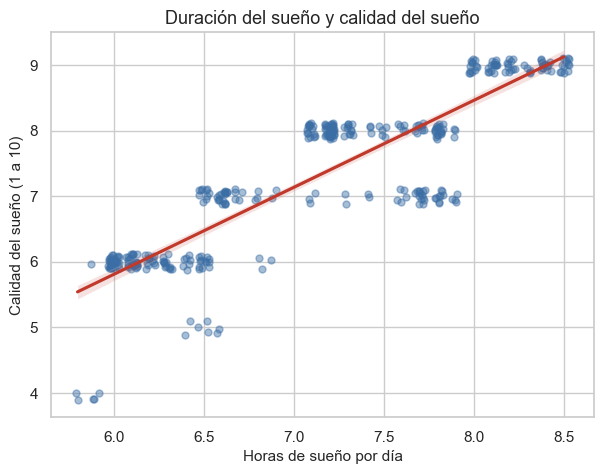

In [38]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=df, x="Sleep Duration", y="Quality of Sleep",
            x_jitter=0.03, y_jitter=0.12,
            scatter_kws={"alpha": 0.45, "s": 25, "color": "#3b6ea5"},
            line_kws={"color": "#c0392b"}, ax=ax)
ax.set_title("Duración del sueño y calidad del sueño")
ax.set_xlabel("Horas de sueño por día")
ax.set_ylabel("Calidad del sueño (1 a 10)")
plt.show()

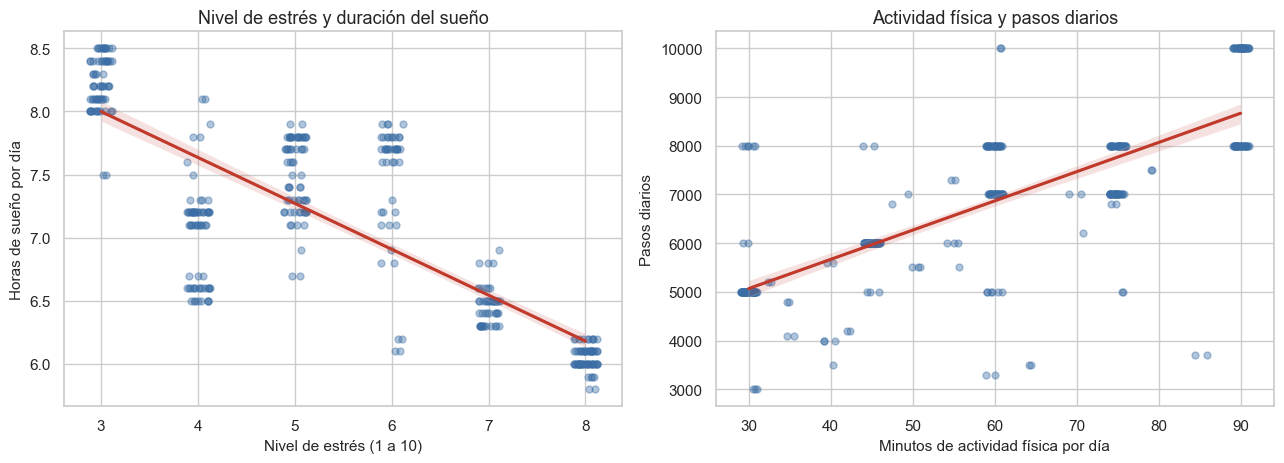

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.regplot(data=df, x="Stress Level", y="Sleep Duration",
            x_jitter=0.12, scatter_kws={"alpha": 0.4, "s": 25, "color": "#3b6ea5"},
            line_kws={"color": "#c0392b"}, ax=axes[0])
axes[0].set_title("Nivel de estrés y duración del sueño")
axes[0].set_xlabel("Nivel de estrés (1 a 10)")
axes[0].set_ylabel("Horas de sueño por día")

sns.regplot(data=df, x="Physical Activity Level", y="Daily Steps",
            x_jitter=1, scatter_kws={"alpha": 0.4, "s": 25, "color": "#3b6ea5"},
            line_kws={"color": "#c0392b"}, ax=axes[1])
axes[1].set_title("Actividad física y pasos diarios")
axes[1].set_xlabel("Minutos de actividad física por día")
axes[1].set_ylabel("Pasos diarios")

plt.tight_layout()
plt.show()

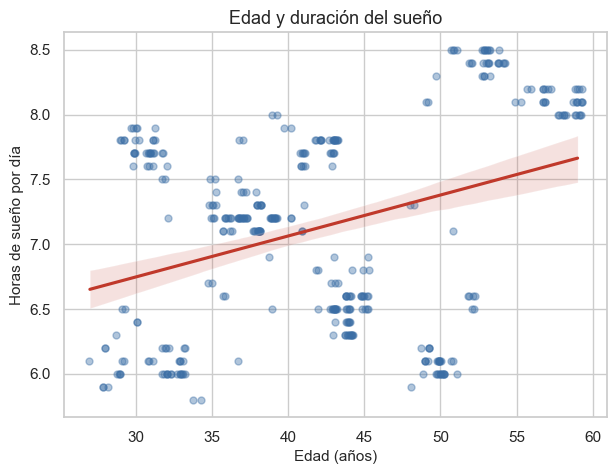

Correlación de Pearson: 0.345


In [40]:
# Una variable sin relación aparente sirve de contraste
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=df, x="Age", y="Sleep Duration",
            x_jitter=0.3, scatter_kws={"alpha": 0.4, "s": 25, "color": "#3b6ea5"},
            line_kws={"color": "#c0392b"}, ax=ax)
ax.set_title("Edad y duración del sueño")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("Horas de sueño por día")
plt.show()

print("Correlación de Pearson:", round(df["Age"].corr(df["Sleep Duration"]), 3))

**Cómo leer estos gráficos.** Compare la inclinación de la línea y la dispersión de los puntos en cada gráfico. Una línea casi horizontal y una nube sin forma indican ausencia de relación lineal: es un resultado tan informativo como encontrar una relación fuerte.

## 6.2 Boxplot por grupos

Combina el boxplot univariante con una variable categórica: se dibuja un boxplot por cada categoría, lo que permite comparar **centro, dispersión y atípicos entre grupos**.

**Qué comparar:**

- Las **medianas** (línea central de cada caja).
- La **altura de las cajas** (dispersión).
- Si las cajas **se solapan mucho** (grupos similares) o poco (grupos distintos).

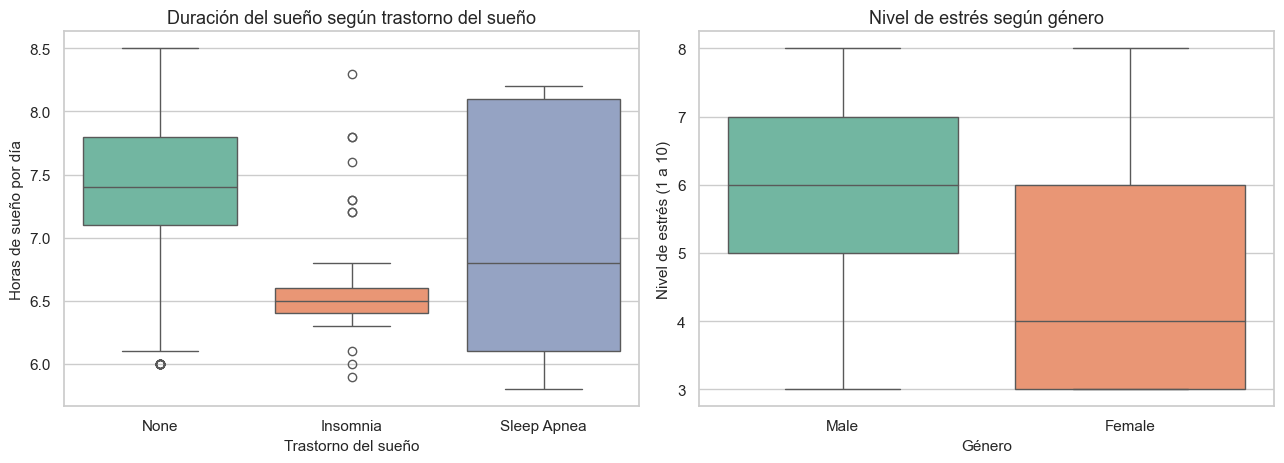

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.boxplot(data=df, x="Sleep Disorder", y="Sleep Duration", order=orden_trastorno,
            hue="Sleep Disorder", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Duración del sueño según trastorno del sueño")
axes[0].set_xlabel("Trastorno del sueño")
axes[0].set_ylabel("Horas de sueño por día")

sns.boxplot(data=df, x="Gender", y="Stress Level",
            hue="Gender", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Nivel de estrés según género")
axes[1].set_xlabel("Género")
axes[1].set_ylabel("Nivel de estrés (1 a 10)")

plt.tight_layout()
plt.show()

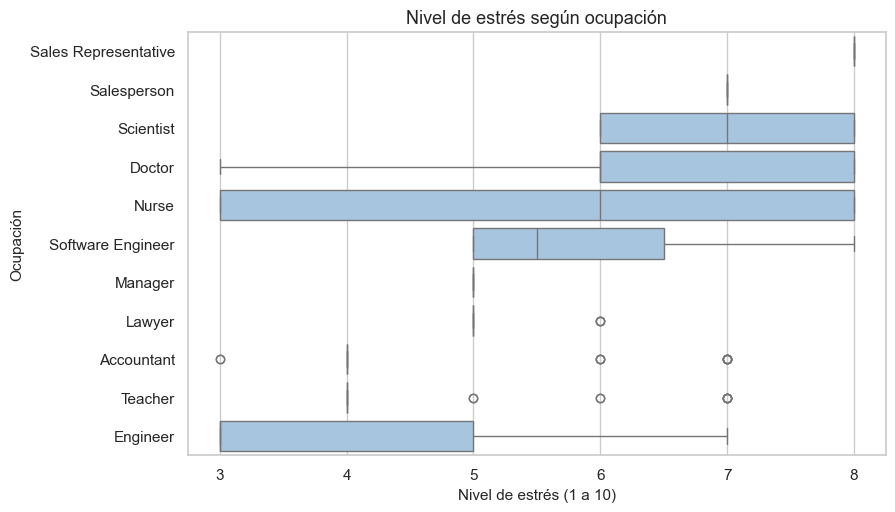

In [42]:
# Variable con muchas categorías: ordenar por mediana facilita la lectura
orden_est = df.groupby("Occupation")["Stress Level"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=df, y="Occupation", x="Stress Level", order=orden_est,
            color="#9fc5e8", ax=ax)
ax.set_title("Nivel de estrés según ocupación")
ax.set_xlabel("Nivel de estrés (1 a 10)")
ax.set_ylabel("Ocupación")
plt.show()

## 6.3 `countplot` con `hue`

Gráfico de barras para dos variables categóricas: el eje principal representa una variable y el color (`hue`) representa la otra.

**Advertencia importante:** si los grupos tienen tamaños distintos, las barras de conteo absoluto **engañan visualmente**. Para comparar la composición entre grupos es preferible usar porcentajes.

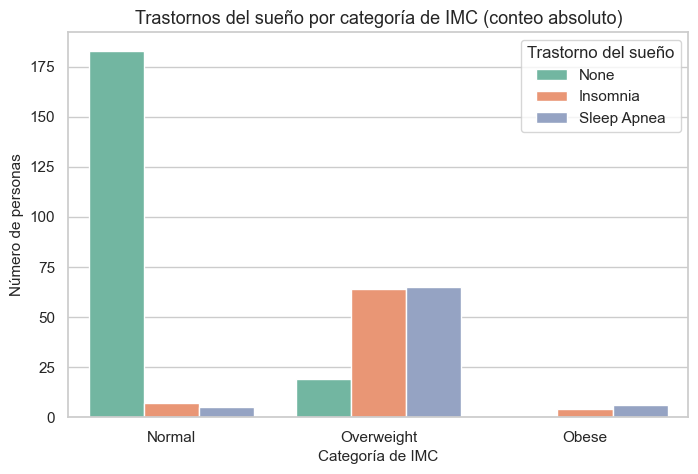

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df, x="BMI Category", hue="Sleep Disorder",
              order=orden_bmi, hue_order=orden_trastorno, palette="Set2", ax=ax)
ax.set_title("Trastornos del sueño por categoría de IMC (conteo absoluto)")
ax.set_xlabel("Categoría de IMC")
ax.set_ylabel("Número de personas")
ax.legend(title="Trastorno del sueño")
plt.show()

**Cómo leer este gráfico.** Observe que la categoría `Normal` tiene muchas más personas que `Obese`, por lo que las barras absolutas no permiten comparar proporciones. El siguiente gráfico corrige este problema.

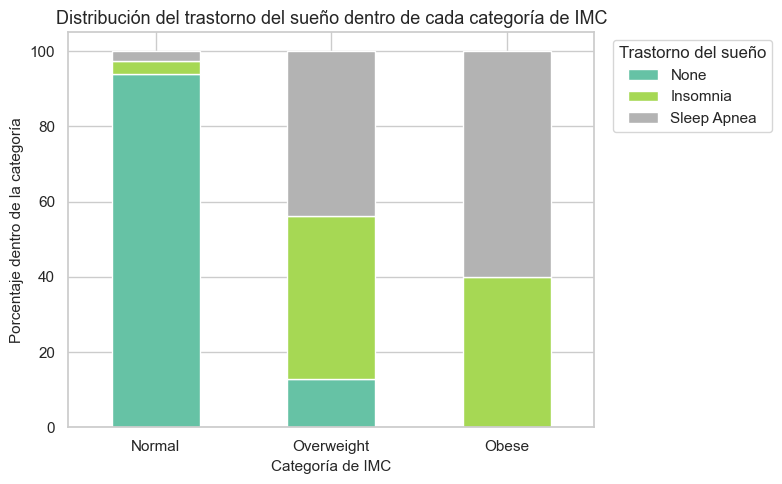

In [44]:
# Barras apiladas al 100 %: comparan la composición dentro de cada grupo
tabla_pct = pd.crosstab(df["BMI Category"], df["Sleep Disorder"], normalize="index") * 100

ax = tabla_pct.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="Set2", edgecolor="white")
ax.set_title("Distribución del trastorno del sueño dentro de cada categoría de IMC")
ax.set_xlabel("Categoría de IMC")
ax.set_ylabel("Porcentaje dentro de la categoría")
ax.legend(title="Trastorno del sueño", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6.4 `crosstab` y porcentajes por grupo

La tabla de contingencia con porcentajes por fila complementa al gráfico anterior con cifras exactas. Una forma útil de presentarla es con un **mapa de calor** que colorea las celdas según su valor.

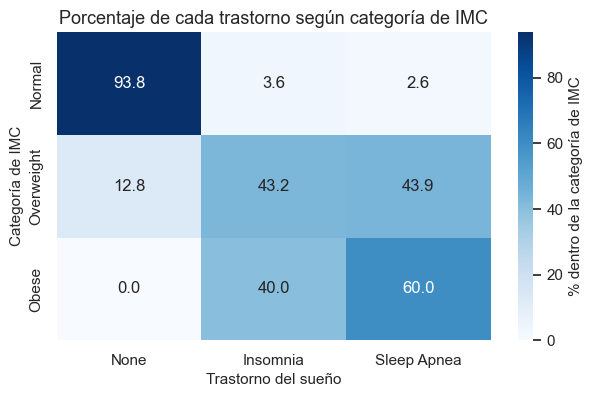

In [45]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(tabla_pct, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% dentro de la categoría de IMC"}, ax=ax)
ax.set_title("Porcentaje de cada trastorno según categoría de IMC")
ax.set_xlabel("Trastorno del sueño")
ax.set_ylabel("Categoría de IMC")
plt.show()

In [46]:
# Estrés y género: porcentajes por grupo con una variable numérica discretizada
df["Stress Group"] = pd.cut(df["Stress Level"], bins=[0, 4, 6, 10],
                            labels=["Bajo (3-4)", "Medio (5-6)", "Alto (7-8)"])

(pd.crosstab(df["Gender"], df["Stress Group"], normalize="index") * 100).round(1)

Stress Group,Bajo (3-4),Medio (5-6),Alto (7-8)
Gender,,,
Female,69.20,5.90,24.90
Male,6.90,54.00,39.20


**Sobre la discretización.** Convertir una variable numérica en categorías (`pd.cut`) permite usar herramientas categóricas, pero **se pierde información**. Los puntos de corte son una decisión del analista y deben justificarse.

## 6.5 Correlación como herramienta exploratoria

Cuando hay varias variables numéricas, se calcula la **matriz de correlación**: una tabla con el coeficiente de cada par. Se visualiza con un mapa de calor.

**Cómo usarla de forma exploratoria:**

1. Identificar los pares con mayor correlación en valor absoluto.
2. **Verificar cada par con un diagrama de dispersión**, porque un coeficiente puede ocultar relaciones curvas o estar distorsionado por atípicos.
3. Formular preguntas e hipótesis; **no sacar conclusiones causales**.

> **Advertencia:** `Systolic` y `Diastolic` están relacionadas por construcción médica, y `Physical Activity Level` y `Daily Steps` miden aspectos cercanos del mismo hábito. Algunas correlaciones altas son esperables y poco informativas.

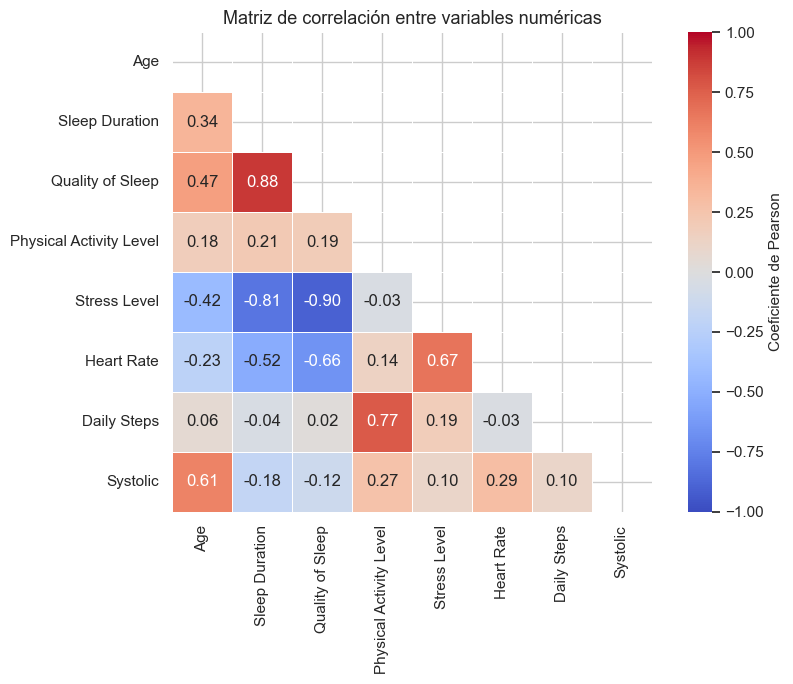

In [47]:
vars_corr = ["Age", "Sleep Duration", "Quality of Sleep", "Physical Activity Level",
             "Stress Level", "Heart Rate", "Daily Steps", "Systolic"]
matriz = df[vars_corr].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
mascara = np.triu(np.ones_like(matriz, dtype=bool))
sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={"label": "Coeficiente de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación entre variables numéricas")
plt.tight_layout()
plt.show()

In [48]:
# Pares ordenados por la magnitud de la correlación
pares = (matriz.where(~mascara).stack().rename("r").reset_index())
pares.columns = ["variable_1", "variable_2", "r"]
pares["|r|"] = pares["r"].abs()
pares.sort_values("|r|", ascending=False).head(8).round(3).reset_index(drop=True)

,variable_1,variable_2,r,|r|
0,Stress Level,Quality of Sleep,-0.90,0.90
1,Quality of Sleep,Sleep Duration,0.88,0.88
2,Stress Level,Sleep Duration,-0.81,0.81
3,Daily Steps,Physical Activity Level,0.77,0.77
4,Heart Rate,Stress Level,0.67,0.67
5,Heart Rate,Quality of Sleep,-0.66,0.66
6,Systolic,Age,0.61,0.61
7,Heart Rate,Sleep Duration,-0.52,0.52


**Cómo leer este resultado.** Se muestra solo el triángulo inferior porque la matriz es simétrica. Los colores intensos indican correlaciones fuertes (rojo positivas, azul negativas). Antes de interpretar cualquier par, se debe confirmar con su diagrama de dispersión.

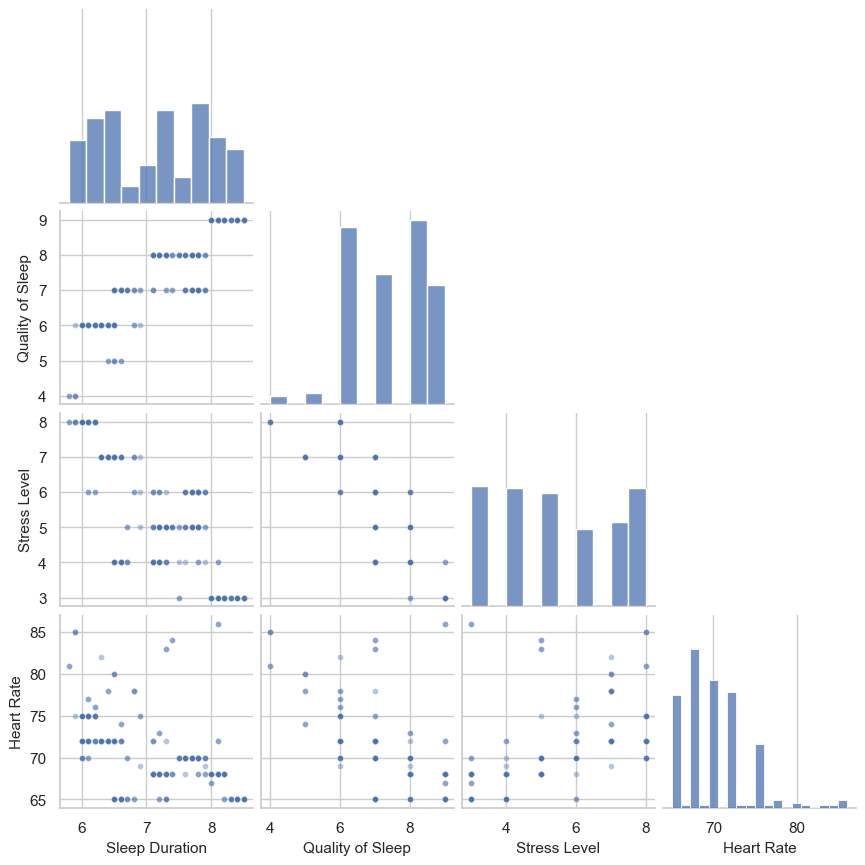

In [49]:
# Vista conjunta de varios pares con pairplot (muestra de variables clave)
sns.pairplot(df[["Sleep Duration", "Quality of Sleep", "Stress Level", "Heart Rate"]],
             corner=True, plot_kws={"alpha": 0.4, "s": 18}, height=2.2)
plt.show()

## 6.6 Ejemplo guiado completo

Ejecutemos el flujo completo con una pregunta concreta.

**Pregunta:** ¿Existe relación entre el nivel de estrés y la duración del sueño?

**Variables:** `Stress Level` (numérica ordinal) y `Sleep Duration` (numérica continua). Combinación: numérica ↔ numérica.

**Análisis:** correlación de Pearson y de Spearman. **Visualización:** diagrama de dispersión.

In [50]:
r_p = df["Stress Level"].corr(df["Sleep Duration"], method="pearson")
r_s = df["Stress Level"].corr(df["Sleep Duration"], method="spearman")
print(f"Pearson:  {r_p:.3f}")
print(f"Spearman: {r_s:.3f}")

print()
print(df.groupby("Stress Level")["Sleep Duration"].agg(["count", "mean"]).round(2))

Pearson:  -0.811
Spearman: -0.811

              count  mean
Stress Level             
3                71  8.23
4                70  7.03
5                67  7.48
6                46  7.45
7                50  6.47
8                70  6.05


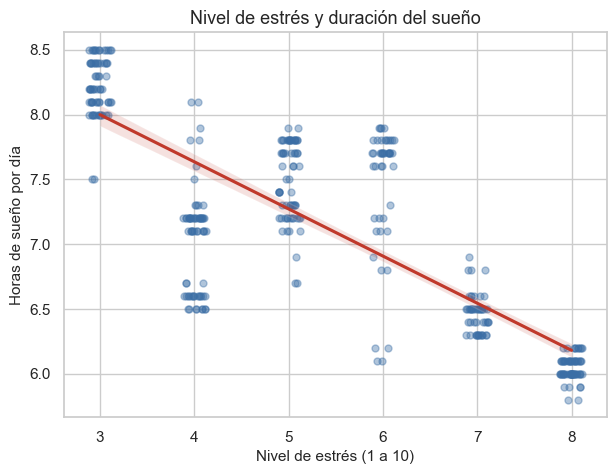

In [51]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=df, x="Stress Level", y="Sleep Duration", x_jitter=0.12,
            scatter_kws={"alpha": 0.4, "s": 25, "color": "#3b6ea5"},
            line_kws={"color": "#c0392b"}, ax=ax)
ax.set_title("Nivel de estrés y duración del sueño")
ax.set_xlabel("Nivel de estrés (1 a 10)")
ax.set_ylabel("Horas de sueño por día")
plt.show()

**Los cuatro niveles aplicados a este caso:**

- **Resultado:** el coeficiente de Pearson entre estrés y duración del sueño es negativo y de magnitud considerable (ver la celda anterior); Spearman arroja un valor similar.
- **Descripción:** a mayor nivel de estrés, menor tiende a ser el número de horas de sueño.
- **Interpretación:** la nube de puntos desciende de izquierda a derecha y la línea de tendencia tiene pendiente negativa; el hecho de que Pearson y Spearman coincidan sugiere una relación aproximadamente lineal y no dominada por valores atípicos. Los promedios por nivel de estrés muestran una disminución progresiva de las horas de sueño.
- **Conclusión:** dentro de este conjunto de datos, las personas con mayor nivel de estrés presentan, en promedio, menos horas de sueño. Esta es una **asociación**; los datos no permiten afirmar que el estrés sea la causa de la reducción del sueño, pues también podría ocurrir lo contrario o intervenir otros factores.

# 7. Parte práctica

## 7.1 Instrucciones

En esta sección cada estudiante (o pareja) **formula sus propias preguntas** y las responde con el flujo completo:

> **Pregunta → variables → análisis → visualización → interpretación → conclusión**

### Variables disponibles

| Variable | Tipo |
|---|---|
| `Sleep Duration` | Numérica continua |
| `Quality of Sleep` | Numérica ordinal |
| `Stress Level` | Numérica ordinal |
| `Physical Activity Level` | Numérica discreta |
| `Age` | Numérica discreta |
| `Gender` | Categórica nominal |
| `BMI Category` | Categórica ordinal |
| `Sleep Disorder` | Categórica nominal |

### Requisitos

1. **Al menos 2 preguntas univariantes** (una numérica y una categórica).
2. **Al menos 3 preguntas bivariantes**, una de cada tipo de combinación: numérica ↔ numérica, categórica ↔ numérica y categórica ↔ categórica.
3. Para cada pregunta se debe completar la **plantilla de análisis** (siguiente sección).
4. Todo gráfico debe tener **título, etiquetas de ejes con unidades** y una **interpretación escrita**.

## 7.2 Qué hace buena a una pregunta

| Característica | Mala pregunta | Buena pregunta |
|---|---|---|
| **Respondible con los datos** | "¿Por qué la gente duerme mal?" | "¿Las personas con insomnio duermen menos horas que las que no tienen trastorno?" |
| **Específica** | "¿Qué influye en el sueño?" | "¿Existe relación entre el nivel de estrés y la calidad del sueño?" |
| **Usa variables concretas** | "¿Es saludable la gente?" | "¿Cómo se distribuye la categoría de IMC según el género?" |
| **Evita causalidad directa** | "¿El estrés causa mal sueño?" | "¿El mal sueño se asocia con mayor estrés?" |

## 7.3 Plantilla de análisis

Copie esta estructura para cada pregunta:

```
PREGUNTA:
VARIABLE(S) Y TIPO:
TIPO DE ANÁLISIS: (univariante / bivariante: tipo de combinación)
TÉCNICA NUMÉRICA:
VISUALIZACIÓN ELEGIDA Y POR QUÉ:
RESULTADO NUMÉRICO:
DESCRIPCIÓN:
INTERPRETACIÓN:
CONCLUSIÓN (acotada al dataset):
LIMITACIONES:
```

## 7.4 Ejemplo resuelto como modelo

**Pregunta:** ¿Las personas con insomnio duermen menos horas que las personas sin trastorno del sueño?

**Variables y tipo:** `Sleep Disorder` (categórica) y `Sleep Duration` (numérica). Combinación categórica ↔ numérica.

**Técnica:** comparación de estadísticos por grupo con `groupby()`.

**Visualización:** boxplot por grupos, porque permite comparar medianas y dispersión.

,count,mean,median,std
Sleep Disorder,,,,
None,219,7.36,7.40,0.73
Insomnia,77,6.59,6.50,0.39


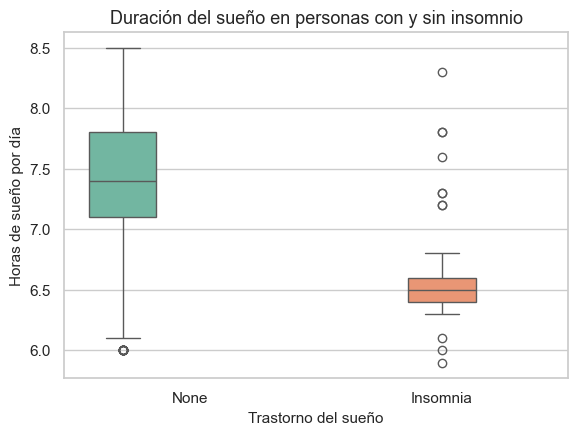

In [52]:
subgrupo = df[df["Sleep Disorder"].isin(["None", "Insomnia"])]

resumen = subgrupo.groupby("Sleep Disorder", observed=True)["Sleep Duration"].agg(
    ["count", "mean", "median", "std"]).round(2)
display(resumen)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.boxplot(data=subgrupo, x="Sleep Disorder", y="Sleep Duration",
            order=["None", "Insomnia"], hue="Sleep Disorder",
            palette="Set2", legend=False, ax=ax)
ax.set_title("Duración del sueño en personas con y sin insomnio")
ax.set_xlabel("Trastorno del sueño")
ax.set_ylabel("Horas de sueño por día")
plt.show()

**Redacción del análisis (ejemplo de formato esperado):**

- **Resultado:** la tabla muestra la media, mediana y desviación estándar de las horas de sueño en cada grupo.
- **Descripción:** el grupo con insomnio presenta un promedio de horas de sueño menor que el grupo sin trastorno (comparar los valores de la columna `mean`).
- **Interpretación:** las cajas de los dos grupos se ubican a alturas distintas y la mediana del grupo con insomnio queda por debajo; el solapamiento entre cajas indica que existen personas con insomnio que duermen tanto como personas sin trastorno.
- **Conclusión:** dentro de este conjunto de datos, las personas con insomnio duermen en promedio menos horas que quienes no presentan trastorno, aunque la diferencia no es uniforme entre individuos.
- **Limitaciones:** no se aplicó ninguna prueba estadística, por lo que no se puede afirmar que la diferencia sea estadísticamente significativa ni generalizarla a otra población.

## 7.5 Banco de preguntas de apoyo (opcional)

Los estudiantes pueden usar estas preguntas como inspiración o formular las propias.

**Univariantes**

1. ¿Cómo se distribuye la edad de los participantes? ¿Hay asimetría?
2. ¿Qué tan dispersa es la actividad física diaria? ¿Hay valores potencialmente atípicos?
3. ¿Qué proporción de participantes presenta algún trastorno del sueño?
4. ¿Cómo se distribuye la calidad del sueño? ¿En qué valores se concentra?

**Bivariantes numérica ↔ numérica**

5. ¿Existe relación entre la actividad física y el nivel de estrés?
6. ¿Existe relación entre la calidad del sueño y el nivel de estrés?
7. ¿La edad se asocia con la duración del sueño o con la actividad física?

**Bivariantes categórica ↔ numérica**

8. ¿El nivel de estrés difiere entre hombres y mujeres?
9. ¿La actividad física difiere según la categoría de IMC?
10. ¿La calidad del sueño difiere según el trastorno del sueño?

**Bivariantes categórica ↔ categórica**

11. ¿Cómo se distribuye el trastorno del sueño según la categoría de IMC?
12. ¿La proporción de cada trastorno del sueño es similar entre hombres y mujeres?
13. ¿La categoría de IMC se distribuye de forma distinta entre hombres y mujeres?

## 7.6 Espacio de trabajo del estudiante

Cada pregunta tiene una celda de texto para la plantilla y celdas de código para el análisis. Agregue las celdas que necesite.

### Pregunta 1: Univariante numérica

```
PREGUNTA:

VARIABLE(S) Y TIPO:

TIPO DE ANÁLISIS:

TÉCNICA NUMÉRICA:

VISUALIZACIÓN ELEGIDA Y POR QUÉ:
```

In [ ]:
# Análisis numérico

In [ ]:
# Visualización (título, ejes con unidades)

```
RESULTADO NUMÉRICO:

DESCRIPCIÓN:

INTERPRETACIÓN:

CONCLUSIÓN (acotada al dataset):

LIMITACIONES:
```

### Pregunta 2: Univariante categórica

```
PREGUNTA:

VARIABLE(S) Y TIPO:

TIPO DE ANÁLISIS:

TÉCNICA NUMÉRICA:

VISUALIZACIÓN ELEGIDA Y POR QUÉ:
```

In [ ]:
# Análisis numérico

In [ ]:
# Visualización (título, ejes con unidades)

```
RESULTADO NUMÉRICO:

DESCRIPCIÓN:

INTERPRETACIÓN:

CONCLUSIÓN (acotada al dataset):

LIMITACIONES:
```

### Pregunta 3: Bivariante numérica - numérica

```
PREGUNTA:

VARIABLE(S) Y TIPO:

TIPO DE ANÁLISIS:

TÉCNICA NUMÉRICA:

VISUALIZACIÓN ELEGIDA Y POR QUÉ:
```

In [ ]:
# Análisis numérico

In [ ]:
# Visualización (título, ejes con unidades)

```
RESULTADO NUMÉRICO:

DESCRIPCIÓN:

INTERPRETACIÓN:

CONCLUSIÓN (acotada al dataset):

LIMITACIONES:
```

### Pregunta 4: Bivariante categórica - numérica

```
PREGUNTA:

VARIABLE(S) Y TIPO:

TIPO DE ANÁLISIS:

TÉCNICA NUMÉRICA:

VISUALIZACIÓN ELEGIDA Y POR QUÉ:
```

In [ ]:
# Análisis numérico

In [ ]:
# Visualización (título, ejes con unidades)

```
RESULTADO NUMÉRICO:

DESCRIPCIÓN:

INTERPRETACIÓN:

CONCLUSIÓN (acotada al dataset):

LIMITACIONES:
```

### Pregunta 5: Bivariante categórica - categórica

```
PREGUNTA:

VARIABLE(S) Y TIPO:

TIPO DE ANÁLISIS:

TÉCNICA NUMÉRICA:

VISUALIZACIÓN ELEGIDA Y POR QUÉ:
```

In [ ]:
# Análisis numérico

In [ ]:
# Visualización (título, ejes con unidades)

```
RESULTADO NUMÉRICO:

DESCRIPCIÓN:

INTERPRETACIÓN:

CONCLUSIÓN (acotada al dataset):

LIMITACIONES:
```

## 7.7 Lista de verificación antes de entregar

- [ ] Cada pregunta es específica y respondible con los datos.
- [ ] Identifiqué correctamente el tipo de cada variable.
- [ ] Elegí la técnica y el gráfico según el tipo de variables.
- [ ] Todos los gráficos tienen título, ejes rotulados y unidades.
- [ ] En categóricas con grupos de distinto tamaño, comparé **porcentajes** y no solo conteos.
- [ ] Revisé el tamaño de cada grupo antes de comparar.
- [ ] Separé resultado, descripción, interpretación y conclusión.
- [ ] La conclusión se limita a este dataset y no afirma causalidad.
- [ ] Mencioné al menos una limitación.

# 8. Cierre

## 8.1 El flujo analítico

El flujo que debe quedar como hábito de trabajo:

> **Pregunta → variables → análisis → visualización → interpretación → conclusión**

| Etapa | Pregunta guía |
|---|---|
| **Pregunta** | ¿Qué quiero saber y es respondible con estos datos? |
| **Variables** | ¿Qué variables intervienen y de qué tipo son? |
| **Análisis** | ¿Qué técnica numérica corresponde a ese tipo de variables? |
| **Visualización** | ¿Qué gráfico muestra mejor lo que busco? |
| **Interpretación** | ¿Qué significan los números y la forma del gráfico? |
| **Conclusión** | ¿Qué puedo afirmar, con qué respaldo y con qué límites? |

## 8.2 Un resultado numérico no es todavía una conclusión

Los cuatro niveles de lenguaje, ilustrados con `Sleep Duration`:

| Nivel | Ejemplo | ¿Qué aporta? |
|---|---|---|
| **Resultado** | `Sleep Duration.mean() = X` | Un número sin contexto. |
| **Descripción** | "La duración promedio del sueño es X horas." | Traduce el número a lenguaje natural con unidades. |
| **Interpretación** | "La distribución muestra que los valores se concentran alrededor de X, aunque existe dispersión..." | Explica la forma, el centro, la dispersión y su significado. |
| **Conclusión** | "Dentro de este conjunto de datos, los participantes presentan..." | Afirma algo acotado, respaldado por la evidencia y con límites explícitos. |

### Características de una buena conclusión

1. Está **respaldada** por resultados y gráficos mostrados.
2. Está **acotada** al conjunto de datos analizado.
3. **No afirma causalidad** a partir de una asociación.
4. **Reconoce limitaciones** (tamaño de grupos, ausencia de pruebas formales, origen de los datos).

## 8.3 Errores frecuentes a evitar

| Error | Por qué es un problema |
|---|---|
| Reportar solo la media | Oculta la dispersión y la forma de la distribución. |
| Interpretar un coeficiente de correlación sin ver el diagrama de dispersión | Puede ocultar relaciones curvas o el efecto de atípicos. |
| Comparar conteos absolutos entre grupos de distinto tamaño | Produce comparaciones engañosas; se deben usar porcentajes. |
| Concluir causalidad a partir de una asociación | Los datos observacionales no permiten establecer causa. |
| Generalizar más allá del conjunto de datos | Las conclusiones solo aplican a las observaciones analizadas. |
| Eliminar atípicos sin justificación | Pueden ser datos legítimos e informativos. |
| Escribir gráficos sin título ni unidades | El lector no puede interpretarlos. |

## 8.4 Pasos siguientes

Este notebook se limitó al análisis exploratorio. Los siguientes temas de la asignatura permitirán:

- Cuantificar la incertidumbre con **intervalos de confianza**.
- Decidir si una diferencia entre grupos es estadísticamente significativa con **pruebas de hipótesis**.
- Medir la asociación entre variables categóricas con la prueba **chi-cuadrado**.
- Modelar relaciones con **regresión**.